# Berlin Urban Heat and Citizen Watering

## Exploratory analysis of the local thesis datasets

**Objective.** Assess data quality, describe citizen watering patterns, normalize
watering by the Berlin tree inventory, and test whether the observed district
distribution is aligned with the available heat indicators.

This is an exploratory notebook. Correlations based on 12 districts are
descriptive and are not causal estimates.

## Analysis plan

1. Audit the watering records and correct known coordinate issues.
2. Describe temporal concentration and concentration across trees.
3. Join watering IDs to the tree cadastre and calculate district-normalized reach.
4. Compare watering metrics with canopy, built surface, population density, and LST.
5. Examine whether watering disproportionately reaches particular tree ages or genera.
6. Separate watering of trees aged <10 and >10 years from planting and compare
   timing with district-year summer temperature.
7. Audit whether the local mortality fields can support heat-mortality analysis.

In [1]:
from pathlib import Path
import sqlite3
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def find_root():
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data/Berlin_trees.gpkg").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")

def display_table(df, formatters=None):
    if formatters is None:
        display(df)
        return
    try:
        display(df.style.format(formatters))
        return
    except AttributeError:
        pass
    formatted = df.copy()
    if isinstance(formatters, str):
        formatters = {column: formatters for column in formatted.columns}
    for column, formatter in formatters.items():
        if column not in formatted:
            continue
        formatted[column] = formatted[column].map(
            lambda value: "" if pd.isna(value) else formatter.format(value)
        )
    display(formatted)

ROOT = find_root()
DATA = ROOT / "data"
FIGURES = ROOT / "output/exploratory/figures"
TABLES = ROOT / "output/exploratory/tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

WATER_FILE = next(DATA.glob("giessdenkiez_bew*sserungsdaten*.csv"))
TREE_FILE = DATA / "Berlin_trees.gpkg"
HEAT_FILE = DATA / "Berlin_heat_population_death_Birth_data.csv"

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"green": "#26734d", "blue": "#337ab7", "orange": "#d9822b", "red": "#b23a48"}

print(f"Project root discovered: {ROOT.name}")
print(f"Watering file: {WATER_FILE.name}")

Project root discovered: MasterThesis
Watering file: giessdenkiez_bewässerungsdaten (1).csv


## 1. Watering data quality and coverage

In [2]:
water_raw = pd.read_csv(WATER_FILE, sep=";")
water = water_raw.copy()
water["timestamp"] = pd.to_datetime(
    water["timestamp"], format="mixed", utc=True, errors="coerce"
)
water["year"] = water["timestamp"].dt.year
water["month"] = water["timestamp"].dt.to_period("M").dt.to_timestamp()
water["litres"] = pd.to_numeric(water["bewaesserungsmenge_in_liter"], errors="coerce")
water["lng"] = pd.to_numeric(water["lng"], errors="coerce")
water["lat"] = pd.to_numeric(water["lat"], errors="coerce")

# Some records have latitude and longitude reversed.
swapped = (
    water["lng"].between(52.3, 52.7)
    & water["lat"].between(13.1, 13.8)
)
water.loc[swapped, ["lng", "lat"]] = water.loc[swapped, ["lat", "lng"]].to_numpy()
water["valid_berlin_coord"] = (
    water["lng"].between(13.0, 14.0)
    & water["lat"].between(52.3, 52.7)
)

source_columns = list(water_raw.columns)
duplicate_mask = water_raw.duplicated(subset=source_columns, keep="first")
water = water.loc[~duplicate_mask].copy()

# 2026 ends in April in the local extract, so exclude it from complete-year comparisons.
water_complete = water[water["timestamp"] < "2026-01-01"].copy()

quality = pd.DataFrame(
    {
        "metric": [
            "Raw events",
            "Exact duplicate rows removed",
            "Unique tree IDs",
            "Coordinate pairs swapped",
            "Missing/invalid Berlin coordinates after correction",
            "Events above 500 L",
            "Events above 1,000 L",
            "First timestamp",
            "Last timestamp",
        ],
        "value": [
            len(water_raw),
            int(duplicate_mask.sum()),
            water["id"].nunique(),
            int(swapped.sum()),
            int((~water["valid_berlin_coord"]).sum()),
            int((water["litres"] > 500).sum()),
            int((water["litres"] > 1000).sum()),
            str(water["timestamp"].min()),
            str(water["timestamp"].max()),
        ],
    }
)
quality.to_csv(TABLES / "watering_data_quality.csv", index=False)
display(quality)

,metric,value
0,Raw events,58847
1,Exact duplicate rows removed,111
2,Unique tree IDs,11278
3,Coordinate pairs swapped,56
4,Missing/invalid Berlin coordinates after corre...,125
5,Events above 500 L,5
6,"Events above 1,000 L",1
7,First timestamp,2020-05-18 20:42:02.524869+00:00
8,Last timestamp,2026-04-30 00:00:00+00:00


,year,events,unique_trees,total_litres,litres_per_event
0,2020,16510,4417,"490,495.000",29.709
1,2021,8235,2159,"251,235.000",30.508
2,2022,18238,4079,"806,691.000",44.231
3,2023,7211,2075,"393,014.000",54.502
4,2024,3679,1056,"166,648.000",45.297
5,2025,4601,1361,"169,904.000",36.928
6,2026,262,108,"7,908.000",30.183


,metric,value
0,Gini of litres across trees,70.0%
1,Top 1% share,17.7%
2,Top 10% share,57.9%


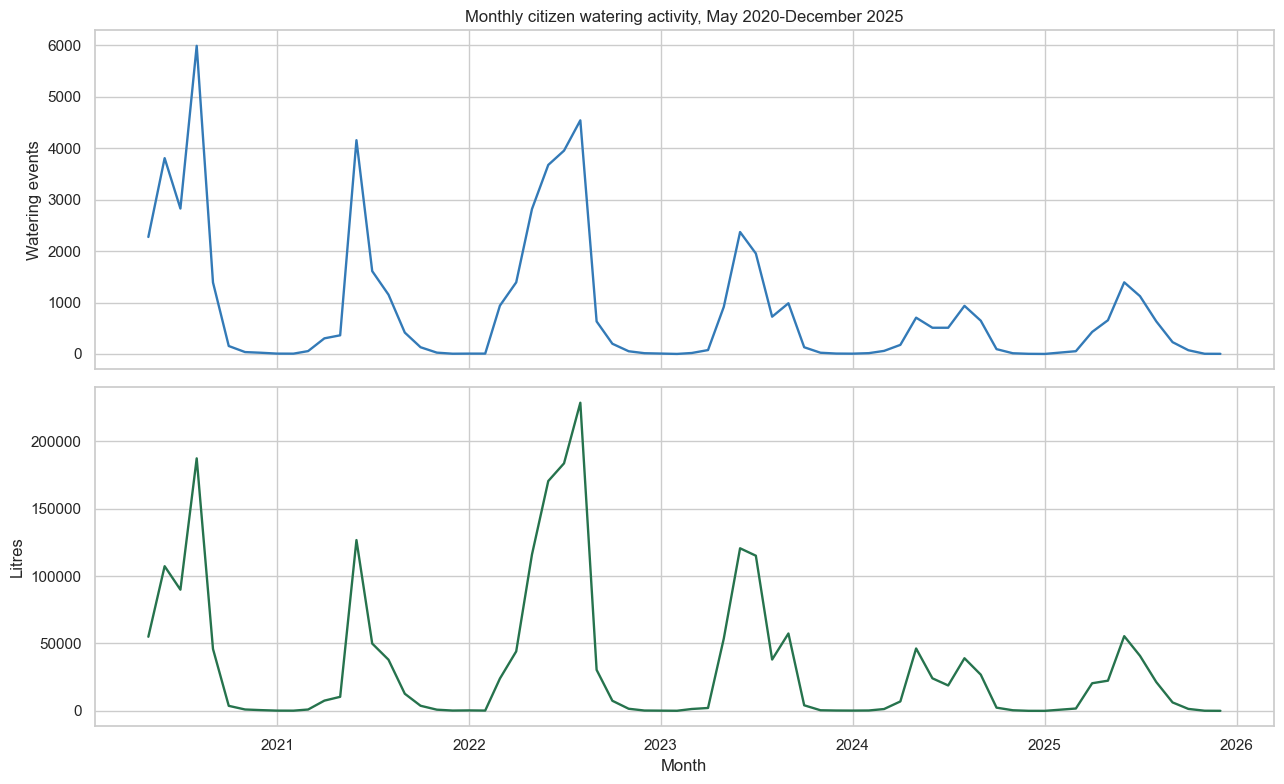

In [3]:
def gini(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values >= 0)]
    if len(values) == 0 or values.sum() == 0:
        return np.nan
    values = np.sort(values)
    n = len(values)
    return (2 * np.sum((np.arange(1, n + 1)) * values) / (n * values.sum())) - (n + 1) / n

annual = (
    water.groupby("year", dropna=False)
    .agg(events=("id", "size"), unique_trees=("id", "nunique"), total_litres=("litres", "sum"))
    .reset_index()
)
annual["litres_per_event"] = annual["total_litres"] / annual["events"]
annual.to_csv(TABLES / "watering_by_year.csv", index=False)

monthly = (
    water_complete.groupby("month")
    .agg(events=("id", "size"), unique_trees=("id", "nunique"), total_litres=("litres", "sum"))
    .reset_index()
)

tree_totals = water_complete.groupby("id")["litres"].sum().sort_values(ascending=False)
top_1_n = max(1, int(np.ceil(len(tree_totals) * 0.01)))
top_10_n = max(1, int(np.ceil(len(tree_totals) * 0.10)))
concentration = pd.DataFrame(
    {
        "metric": ["Gini of litres across trees", "Top 1% share", "Top 10% share"],
        "value": [
            gini(tree_totals),
            tree_totals.head(top_1_n).sum() / tree_totals.sum(),
            tree_totals.head(top_10_n).sum() / tree_totals.sum(),
        ],
    }
)
concentration.to_csv(TABLES / "watering_concentration.csv", index=False)

display(annual)
display_table(concentration, {"value": "{:.1%}"})

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(monthly["month"], monthly["events"], color=COLORS["blue"], linewidth=1.7)
axes[0].set_ylabel("Watering events")
axes[0].set_title("Monthly citizen watering activity, May 2020-December 2025")
axes[1].plot(monthly["month"], monthly["total_litres"], color=COLORS["green"], linewidth=1.7)
axes[1].set_ylabel("Litres")
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.savefig(FIGURES / "01_monthly_watering_activity.png", dpi=180, bbox_inches="tight")
plt.show()

## 2. Tree-cadastre linkage and district-normalized reach

In [4]:
con = sqlite3.connect(f"file:{TREE_FILE}?mode=ro", uri=True)

inventory_by_district = pd.read_sql_query(
    '''
    SELECT bezirk, source_layer,
           COUNT(*) AS inventory_rows,
           COUNT(DISTINCT pitid) AS inventory_trees,
           SUM(CASE WHEN pflanzjahr IS NULL OR pflanzjahr = '' THEN 1 ELSE 0 END) AS missing_plant_year
    FROM Berlin_trees
    WHERE bezirk IS NOT NULL AND bezirk != ''
    GROUP BY bezirk, source_layer
    ''',
    con,
)

watering_ids = set(water["id"].dropna().unique())
matched_parts = []
columns = (
    "pitid, bezirk, source_layer, pflanzjahr, standalter, kronedurch, "
    "stammumfg, baumhoehe, art_dtsch, gattung_deutsch"
)
for chunk in pd.read_sql_query(f"SELECT {columns} FROM Berlin_trees", con, chunksize=200_000):
    matched_parts.append(chunk[chunk["pitid"].isin(watering_ids)])
matched_trees = pd.concat(matched_parts, ignore_index=True)

gpkg_metadata = pd.read_sql_query(
    '''
    SELECT c.table_name, c.srs_id, c.min_x, c.min_y, c.max_x, c.max_y,
           g.geometry_type_name
    FROM gpkg_contents c
    LEFT JOIN gpkg_geometry_columns g ON c.table_name = g.table_name
    WHERE c.table_name = 'Berlin_trees'
    ''',
    con,
)

match_summary = pd.DataFrame(
    {
        "metric": [
            "Unique watering IDs",
            "Matched cadastre IDs",
            "Match rate",
            "Unmatched IDs",
            "Matched street-tree IDs",
            "Matched park-tree IDs",
        ],
        "value": [
            len(watering_ids),
            matched_trees["pitid"].nunique(),
            matched_trees["pitid"].nunique() / len(watering_ids),
            len(watering_ids) - matched_trees["pitid"].nunique(),
            matched_trees.loc[
                matched_trees["source_layer"] == "baumbestand:strassenbaeume", "pitid"
            ].nunique(),
            matched_trees.loc[
                matched_trees["source_layer"] == "baumbestand:anlagenbaeume", "pitid"
            ].nunique(),
        ],
    }
)
match_summary.to_csv(TABLES / "tree_id_match_summary.csv", index=False)

display(match_summary)
display(gpkg_metadata)
print(
    "CRS warning: the GeoPackage declares EPSG:4326, but the stored extent "
    "(approximately 370,000-415,000 E and 5,800,000-5,836,000 N) is projected. "
    "This is consistent with UTM-style coordinates and must be corrected before spatial joins."
)

,metric,value
0,Unique watering IDs,"11,278.000"
1,Matched cadastre IDs,"11,160.000"
2,Match rate,0.990
3,Unmatched IDs,118.000
4,Matched street-tree IDs,"10,332.000"
5,Matched park-tree IDs,828.000


,table_name,srs_id,min_x,min_y,max_x,max_y,geometry_type_name
0,Berlin_trees,4326,"370,189.476","5,799,846.613","415,496.892","5,835,818.974",POINT


CRS warning: the GeoPackage declares EPSG:4326, but the stored extent (approximately 370,000-415,000 E and 5,800,000-5,836,000 N) is projected. This is consistent with UTM-style coordinates and must be corrected before spatial joins.


,bezirk,inventory_trees,unique_watered_trees,reach_pct,street_reach_pct,total_litres,litres_per_inventory_tree
1,Friedrichshain-Kreuzberg,41768,1693,4.05,8.40,"280,579",6.72
4,Mitte,67706,1643,2.43,5.94,"355,668",5.25
10,Tempelhof-Schöneberg,62334,1462,2.35,3.92,"310,100",4.97
0,Charlottenburg-Wilmersdorf,88758,1388,1.56,3.25,"321,831",3.63
6,Pankow,99561,1436,1.44,2.96,"259,182",2.60
5,Neukölln,57881,773,1.34,3.46,"168,545",2.91
11,Treptow-Köpenick,78295,609,0.78,1.34,"119,599",1.53
2,Lichtenberg,81916,611,0.75,1.75,"108,142",1.32
9,Steglitz-Zehlendorf,115424,831,0.72,1.35,"186,829",1.62
7,Reinickendorf,90869,408,0.45,0.88,"92,568",1.02


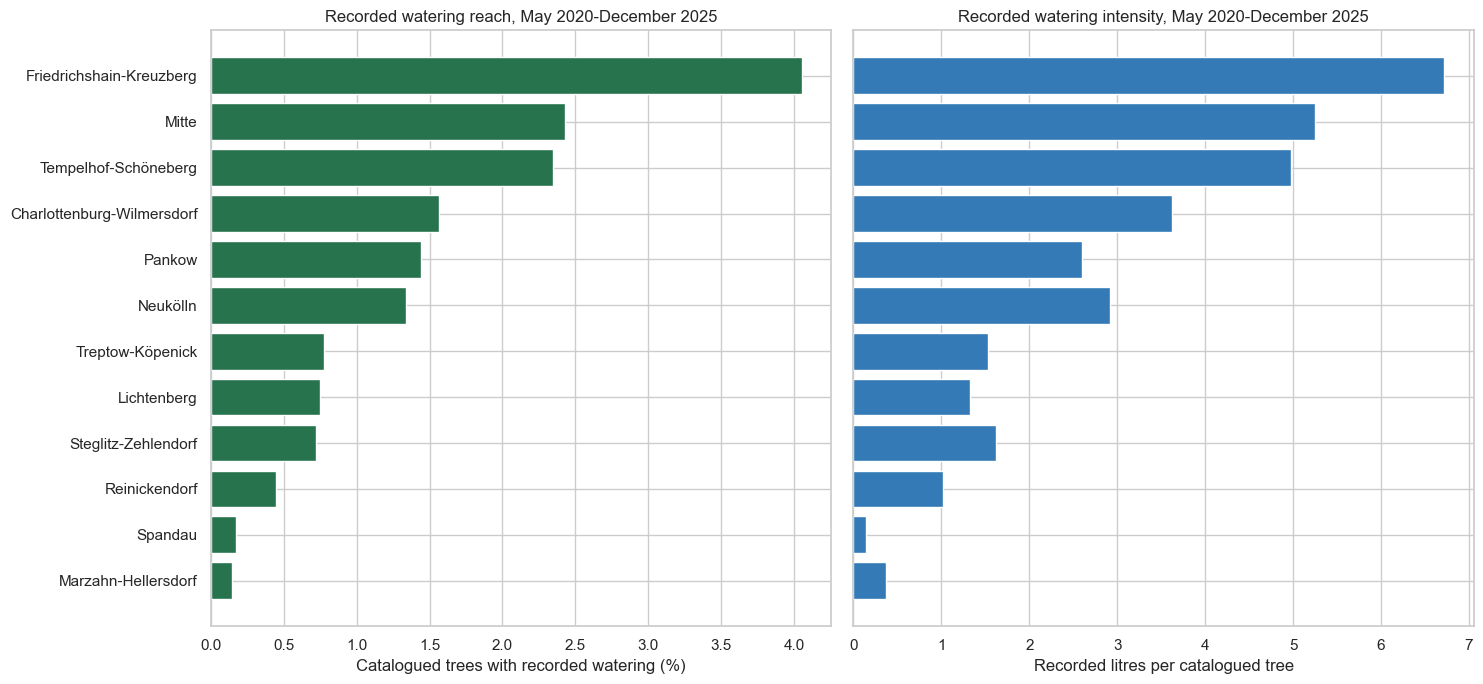

In [5]:
matched_attrs = matched_trees.drop_duplicates("pitid")
water_matched = water_complete.merge(
    matched_attrs,
    left_on="id",
    right_on="pitid",
    how="inner",
    suffixes=("_event", "_tree"),
)

district_inventory = (
    inventory_by_district.groupby("bezirk", as_index=False)
    .agg(inventory_trees=("inventory_trees", "sum"))
)
street_inventory = (
    inventory_by_district[
        inventory_by_district["source_layer"] == "baumbestand:strassenbaeume"
    ][["bezirk", "inventory_trees"]]
    .rename(columns={"inventory_trees": "street_inventory_trees"})
)

district_water = (
    water_matched.groupby("bezirk_tree", as_index=False)
    .agg(
        events=("id", "size"),
        unique_watered_trees=("id", "nunique"),
        total_litres=("litres", "sum"),
    )
    .rename(columns={"bezirk_tree": "bezirk"})
)
district_street_water = (
    water_matched[
        water_matched["source_layer"] == "baumbestand:strassenbaeume"
    ]
    .groupby("bezirk_tree", as_index=False)["id"]
    .nunique()
    .rename(columns={"bezirk_tree": "bezirk", "id": "watered_street_trees"})
)

district_metrics = (
    district_inventory.merge(street_inventory, on="bezirk", how="left")
    .merge(district_water, on="bezirk", how="left")
    .merge(district_street_water, on="bezirk", how="left")
)
district_metrics["reach_pct"] = (
    100 * district_metrics["unique_watered_trees"] / district_metrics["inventory_trees"]
)
district_metrics["street_reach_pct"] = (
    100 * district_metrics["watered_street_trees"] / district_metrics["street_inventory_trees"]
)
district_metrics["litres_per_inventory_tree"] = (
    district_metrics["total_litres"] / district_metrics["inventory_trees"]
)
district_metrics["events_per_1000_inventory"] = (
    1000 * district_metrics["events"] / district_metrics["inventory_trees"]
)
district_metrics = district_metrics.sort_values("reach_pct", ascending=False)
district_metrics.to_csv(TABLES / "district_watering_metrics_2020_2025.csv", index=False)

display_table(
    district_metrics[
        [
            "bezirk",
            "inventory_trees",
            "unique_watered_trees",
            "reach_pct",
            "street_reach_pct",
            "total_litres",
            "litres_per_inventory_tree",
        ]
    ],
    {
        "reach_pct": "{:.2f}",
        "street_reach_pct": "{:.2f}",
        "total_litres": "{:,.0f}",
        "litres_per_inventory_tree": "{:.2f}",
    },
)

plot_data = district_metrics.sort_values("reach_pct")
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
axes[0].barh(plot_data["bezirk"], plot_data["reach_pct"], color=COLORS["green"])
axes[0].set_xlabel("Catalogued trees with recorded watering (%)")
axes[0].set_title("Recorded watering reach, May 2020-December 2025")
axes[1].barh(
    plot_data["bezirk"],
    plot_data["litres_per_inventory_tree"],
    color=COLORS["blue"],
)
axes[1].set_xlabel("Recorded litres per catalogued tree")
axes[1].set_title("Recorded watering intensity, May 2020-December 2025")
plt.tight_layout()
plt.savefig(FIGURES / "02_district_normalized_watering.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Relationship with the available heat indicators

,urban_metric,outcome,spearman_rho,p_value
0,TreeCover_Pct,Landsat_LST_C,-0.84,0.001
1,BuiltSurface_Pct,Landsat_LST_C,0.64,0.024
2,PopulationDensity_per_km2,Landsat_LST_C,0.66,0.018


,heat_or_urban_metric,watering_metric,spearman_rho,p_value
0,Landsat_LST_C,reach_pct,0.30,0.342
1,Landsat_LST_C,litres_per_inventory_tree,0.24,0.457
2,Landsat_LST_C,events_per_1000_inventory,0.24,0.443
3,TreeCover_Pct,reach_pct,-0.50,0.095
4,TreeCover_Pct,litres_per_inventory_tree,-0.48,0.118
5,TreeCover_Pct,events_per_1000_inventory,-0.46,0.131
6,BuiltSurface_Pct,reach_pct,0.64,0.024
7,BuiltSurface_Pct,litres_per_inventory_tree,0.71,0.010
8,BuiltSurface_Pct,events_per_1000_inventory,0.68,0.015
9,PopulationDensity_per_km2,reach_pct,0.71,0.010


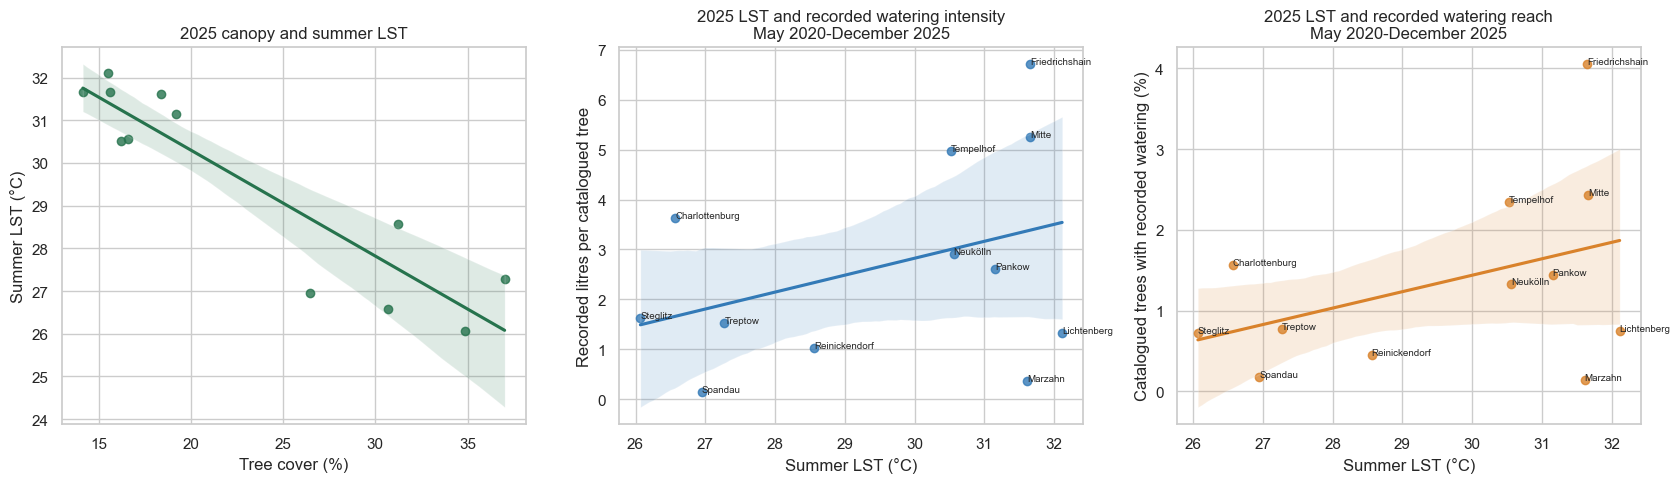

In [6]:
boroughs = [
    "Mitte", "Friedrichshain-Kreuzberg", "Pankow",
    "Charlottenburg-Wilmersdorf", "Spandau", "Steglitz-Zehlendorf",
    "Tempelhof-Schöneberg", "Neukölln", "Treptow-Köpenick",
    "Marzahn-Hellersdorf", "Lichtenberg", "Reinickendorf",
]

heat_raw = pd.read_csv(HEAT_FILE)
heat = heat_raw[
    heat_raw["District"].isin(boroughs)
    & (heat_raw["fclass"] == "admin_level9")
    & (heat_raw["season"] == "Summer")
].copy()

key_counts = heat.groupby(["District", "Year"]).size()
assert len(heat) == 36 and key_counts.eq(1).all(), "Unexpected borough-year structure."

heat_2020 = heat[heat["Year"] == 2020].copy()
heat_2025 = heat[heat["Year"] == 2025].copy()

district_join = district_metrics.merge(
    heat_2025[
        [
            "District", "Landsat_LST_C", "TreeCover_Pct", "BuiltSurface_Pct",
            "PopulationDensity_per_km2", "OldAgeQuotient",
        ]
    ],
    left_on="bezirk",
    right_on="District",
    how="inner",
)

baseline_rows = []
for metric in ["TreeCover_Pct", "BuiltSurface_Pct", "PopulationDensity_per_km2"]:
    rho, p = spearmanr(
        district_join[metric], district_join["Landsat_LST_C"], nan_policy="omit"
    )
    baseline_rows.append(
        {
            "urban_metric": metric,
            "outcome": "Landsat_LST_C",
            "spearman_rho": rho,
            "p_value": p,
        }
    )
baseline_correlations = pd.DataFrame(baseline_rows)
baseline_correlations.to_csv(TABLES / "heat_structure_correlations.csv", index=False)

metrics_y = ["reach_pct", "litres_per_inventory_tree", "events_per_1000_inventory"]
metrics_x = ["Landsat_LST_C", "TreeCover_Pct", "BuiltSurface_Pct", "PopulationDensity_per_km2"]
rows = []
for x in metrics_x:
    for y in metrics_y:
        rho, p = spearmanr(district_join[x], district_join[y], nan_policy="omit")
        rows.append({"heat_or_urban_metric": x, "watering_metric": y, "spearman_rho": rho, "p_value": p})
correlations = pd.DataFrame(rows)
correlations.to_csv(TABLES / "district_spearman_correlations.csv", index=False)

display_table(baseline_correlations, {"spearman_rho": "{:.2f}", "p_value": "{:.3f}"})
display_table(correlations, {"spearman_rho": "{:.2f}", "p_value": "{:.3f}"})

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.regplot(data=heat_2025, x="TreeCover_Pct", y="Landsat_LST_C", ax=axes[0], color=COLORS["green"])
axes[0].set_title("2025 canopy and summer LST")
axes[0].set_xlabel("Tree cover (%)")
axes[0].set_ylabel("Summer LST (°C)")

sns.regplot(
    data=district_join,
    x="Landsat_LST_C",
    y="litres_per_inventory_tree",
    ax=axes[1],
    color=COLORS["blue"],
)
axes[1].set_title("2025 LST and recorded watering intensity\nMay 2020-December 2025")
axes[1].set_xlabel("Summer LST (°C)")
axes[1].set_ylabel("Recorded litres per catalogued tree")

sns.regplot(
    data=district_join,
    x="Landsat_LST_C",
    y="reach_pct",
    ax=axes[2],
    color=COLORS["orange"],
)
axes[2].set_title("2025 LST and recorded watering reach\nMay 2020-December 2025")
axes[2].set_xlabel("Summer LST (°C)")
axes[2].set_ylabel("Catalogued trees with recorded watering (%)")

for ax, y_column in zip(
    axes[1:],
    ["litres_per_inventory_tree", "reach_pct"],
):
    for _, row in district_join.iterrows():
        ax.annotate(
            row["bezirk"].split("-")[0],
            (row["Landsat_LST_C"], row[y_column]),
            fontsize=7,
        )

plt.tight_layout()
plt.savefig(FIGURES / "03_heat_watering_alignment.png", dpi=180, bbox_inches="tight")
plt.show()

district_join.to_csv(TABLES / "district_heat_watering_join.csv", index=False)

The comparison above uses only 12 observations and combines cumulative watering
with a 2025 heat snapshot. It is useful for detecting obvious misalignment, but
not for estimating a watering effect. Daily weather and event-matched thermal
imagery are required for the main model.

## 4. Which trees receive watering?

,age_class,inventory_share,watered_share,representation_ratio
0,20-39,29.8%,30.1%,1.01
1,60+,28.9%,17.4%,0.60
2,40-59,27.2%,21.9%,0.80
3,10-19,7.7%,18.1%,2.36
4,0-9,6.4%,12.4%,1.94


,gattung_deutsch,inventory_trees,watered_trees,reach_pct
4,Birne,2366,193.000000,8.16
29,Hasel,8523,504.000000,5.91
82,Weißdorn,5416,320.000000,5.91
51,Mehlbeere,4429,199.000000,4.49
27,Hainbuche,8088,338.000000,4.18
23,Gleditschie,3131,124.000000,3.96
1,Amberbaum,2155,63.000000,2.92
46,Linde,150148,4037.000000,2.69
77,Ulme,8087,178.000000,2.20
0,Ahorn,89091,1879.000000,2.11


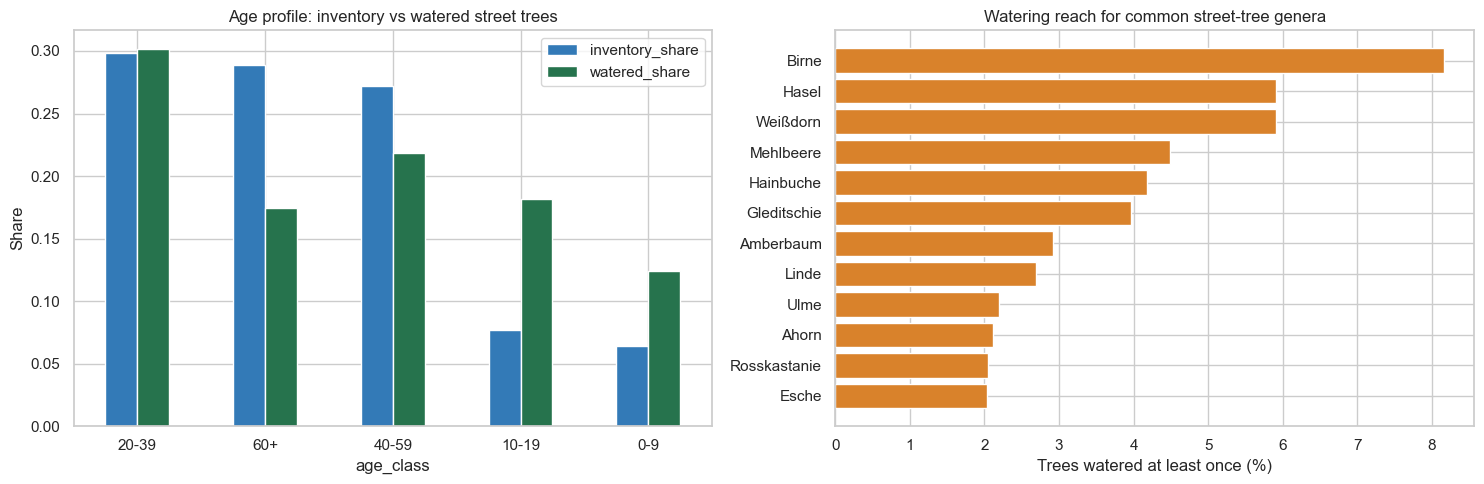

In [7]:
def age_class(values):
    return pd.cut(
        pd.to_numeric(values, errors="coerce"),
        bins=[-np.inf, 9, 19, 39, 59, np.inf],
        labels=["0-9", "10-19", "20-39", "40-59", "60+"],
    )

street_inventory_age = pd.read_sql_query(
    '''
    SELECT standalter
    FROM Berlin_trees
    WHERE source_layer = 'baumbestand:strassenbaeume'
      AND standalter IS NOT NULL
      AND bezirk IS NOT NULL
    ''',
    con,
)
street_inventory_age["age_class"] = age_class(street_inventory_age["standalter"])

watered_street = matched_attrs[
    matched_attrs["source_layer"] == "baumbestand:strassenbaeume"
].copy()
watered_street["age_class"] = age_class(watered_street["standalter"])

age_compare = pd.concat(
    [
        street_inventory_age["age_class"].value_counts(normalize=True).rename("inventory_share"),
        watered_street["age_class"].value_counts(normalize=True).rename("watered_share"),
    ],
    axis=1,
).reset_index(names="age_class")
age_compare["representation_ratio"] = age_compare["watered_share"] / age_compare["inventory_share"]
age_compare.to_csv(TABLES / "street_tree_age_selectivity.csv", index=False)

inventory_genus = pd.read_sql_query(
    '''
    SELECT gattung_deutsch, COUNT(DISTINCT pitid) AS inventory_trees
    FROM Berlin_trees
    WHERE source_layer = 'baumbestand:strassenbaeume'
      AND gattung_deutsch IS NOT NULL
      AND gattung_deutsch != ''
      AND bezirk IS NOT NULL
    GROUP BY gattung_deutsch
    ''',
    con,
)
watered_genus = (
    watered_street.groupby("gattung_deutsch", as_index=False)["pitid"]
    .nunique()
    .rename(columns={"pitid": "watered_trees"})
)
genus_reach = inventory_genus.merge(watered_genus, on="gattung_deutsch", how="left").fillna(0)
genus_reach["reach_pct"] = 100 * genus_reach["watered_trees"] / genus_reach["inventory_trees"]
genus_reach = genus_reach[genus_reach["inventory_trees"] >= 2_000].sort_values("reach_pct", ascending=False)
genus_reach.to_csv(TABLES / "street_tree_genus_reach.csv", index=False)

display_table(age_compare, {"inventory_share": "{:.1%}", "watered_share": "{:.1%}", "representation_ratio": "{:.2f}"})
display_table(genus_reach.head(15), {"reach_pct": "{:.2f}"})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
age_plot = age_compare.set_index("age_class")[["inventory_share", "watered_share"]]
age_plot.plot(kind="bar", ax=axes[0], color=[COLORS["blue"], COLORS["green"]])
axes[0].set_ylabel("Share")
axes[0].set_title("Age profile: inventory vs watered street trees")
axes[0].tick_params(axis="x", rotation=0)

top_genus = genus_reach.head(12).sort_values("reach_pct")
axes[1].barh(top_genus["gattung_deutsch"], top_genus["reach_pct"], color=COLORS["orange"])
axes[1].set_xlabel("Trees watered at least once (%)")
axes[1].set_title("Watering reach for common street-tree genera")

plt.tight_layout()
plt.savefig(FIGURES / "04_tree_selectivity.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Watering timing by tree age and temperature alignment

This section defines tree age at watering as `watering year - planting year`.
Events are split into trees younger than 10 years and trees older than 10 years;
exactly 10-year-old and unknown-age events are audited but excluded from the
binary comparison.

The available temperature outcome is borough-level summer temperature in 2020
and 2025. Results below therefore describe alignment between logged watering and
temperature, not a causal cooling effect of watering.

In [8]:
age_panel = water_matched.copy()
plant_year_event = pd.to_numeric(age_panel["pflanzjahr_event"], errors="coerce")
plant_year_tree = pd.to_numeric(age_panel["pflanzjahr_tree"], errors="coerce")
age_panel["plant_year_for_age"] = plant_year_event.combine_first(plant_year_tree)
age_panel["age_at_watering"] = age_panel["year"] - age_panel["plant_year_for_age"]
age_panel.loc[~age_panel["age_at_watering"].between(0, 250), "age_at_watering"] = np.nan
age_panel["watering_age_group"] = np.select(
    [
        age_panel["age_at_watering"].lt(10),
        age_panel["age_at_watering"].gt(10),
        age_panel["age_at_watering"].eq(10),
    ],
    ["young_lt10", "mature_gt10", "age_10_exact"],
    default="unknown",
)

age_group_order = ["young_lt10", "mature_gt10", "age_10_exact", "unknown"]
age_group_labels = {
    "young_lt10": "<10 years from planting",
    "mature_gt10": ">10 years from planting",
    "age_10_exact": "exactly 10 years",
    "unknown": "unknown planting year",
}
age_panel["watering_age_group"] = pd.Categorical(
    age_panel["watering_age_group"],
    categories=age_group_order,
    ordered=True,
)

age_group_summary = (
    age_panel.groupby("watering_age_group", observed=True)
    .agg(
        events=("id", "size"),
        unique_trees=("id", "nunique"),
        total_litres=("litres", "sum"),
        median_age_at_watering=("age_at_watering", "median"),
    )
    .reset_index()
)
age_group_summary["age_group_label"] = age_group_summary["watering_age_group"].map(age_group_labels)
age_group_summary["event_share"] = age_group_summary["events"] / age_group_summary["events"].sum()
age_group_summary["litre_share"] = age_group_summary["total_litres"] / age_group_summary["total_litres"].sum()
age_group_summary = age_group_summary[
    [
        "watering_age_group",
        "age_group_label",
        "events",
        "unique_trees",
        "total_litres",
        "event_share",
        "litre_share",
        "median_age_at_watering",
    ]
]
age_group_summary.to_csv(TABLES / "watering_age_group_summary.csv", index=False)

age_focus = age_panel[
    age_panel["watering_age_group"].isin(["young_lt10", "mature_gt10"])
].copy()
age_focus["watering_age_group"] = age_focus["watering_age_group"].cat.remove_unused_categories()
age_focus["calendar_month"] = age_focus["timestamp"].dt.month
age_focus["calendar_month_name"] = age_focus["timestamp"].dt.month_name().str.slice(stop=3)

age_calendar = (
    age_focus.groupby(["watering_age_group", "calendar_month", "calendar_month_name"], observed=True)
    .agg(events=("id", "size"), unique_trees=("id", "nunique"), total_litres=("litres", "sum"))
    .reset_index()
)
age_calendar["event_share_within_group"] = age_calendar.groupby(
    "watering_age_group", observed=True
)["events"].transform(lambda values: values / values.sum())
age_calendar["litre_share_within_group"] = age_calendar.groupby(
    "watering_age_group", observed=True
)["total_litres"].transform(lambda values: values / values.sum())
age_calendar.to_csv(TABLES / "watering_age_calendar_month.csv", index=False)

age_year_timing = (
    age_focus.groupby(["watering_age_group", "year"], observed=True)
    .agg(events=("id", "size"), unique_trees=("id", "nunique"), total_litres=("litres", "sum"))
    .reset_index()
)
age_year_timing.to_csv(TABLES / "watering_age_yearly.csv", index=False)

display_table(
    age_group_summary,
    {
        "events": "{:,.0f}",
        "unique_trees": "{:,.0f}",
        "total_litres": "{:,.0f}",
        "event_share": "{:.1%}",
        "litre_share": "{:.1%}",
        "median_age_at_watering": "{:.1f}",
    },
)
display_table(
    age_calendar.pivot(
        index="calendar_month_name",
        columns="watering_age_group",
        values="event_share_within_group",
    )
    .reindex(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]),
    "{:.1%}",
)

,watering_age_group,age_group_label,events,unique_trees,total_litres,event_share,litre_share,median_age_at_watering
0,young_lt10,<10 years from planting,"13,237","2,382","582,862",22.9%,25.9%,5.0
1,mature_gt10,>10 years from planting,"43,047","8,574","1,597,581",74.5%,71.0%,34.0
2,age_10_exact,exactly 10 years,"1,292",339,"58,181",2.2%,2.6%,10.0
3,unknown,unknown planting year,210,59,"10,878",0.4%,0.5%,nan


watering_age_group,young_lt10,mature_gt10
calendar_month_name,,
Jan,0.0%,0.0%
Feb,0.0%,0.1%
Mar,1.1%,2.2%
Apr,3.7%,4.2%
May,13.4%,13.3%
Jun,26.7%,27.4%
Jul,20.9%,20.3%
Aug,24.2%,23.7%
Sep,8.7%,7.0%


,District,Year,Landsat_LST_C,young_lt10_reach_pct,mature_gt10_reach_pct,young_lt10_litres_per_inventory_tree,mature_gt10_litres_per_inventory_tree
6,Lichtenberg,2020,33.18,0.70,0.40,1.05,0.42
0,Friedrichshain-Kreuzberg,2020,33.08,5.47,1.93,10.97,1.96
5,Neukölln,2020,32.69,3.12,1.11,3.36,1.62
7,Tempelhof-Schöneberg,2020,32.50,3.25,1.07,4.22,1.15
2,Mitte,2020,32.29,2.87,0.70,5.45,0.76
8,Pankow,2020,31.27,2.65,0.53,2.22,0.49
4,Marzahn-Hellersdorf,2020,30.96,0.00,0.00,0.00,0.00
3,Reinickendorf,2020,26.51,0.52,0.11,0.59,0.11
9,Steglitz-Zehlendorf,2020,26.15,1.05,0.38,1.93,0.27
1,Spandau,2020,26.08,0.11,0.09,0.22,0.04


,temperature_metric,watering_age_metric,n,spearman_rho,p_value
0,Landsat_LST_C,young_lt10_reach_pct,24,0.33,0.118
1,Landsat_LST_C,mature_gt10_reach_pct,24,0.35,0.097
2,Landsat_LST_C,young_lt10_litres_per_inventory_tree,24,0.32,0.129
3,Landsat_LST_C,mature_gt10_litres_per_inventory_tree,24,0.39,0.063
4,Landsat_LST_C,young_lt10_events_per_1000_inventory,24,0.27,0.203
5,Landsat_LST_C,mature_gt10_events_per_1000_inventory,24,0.34,0.103


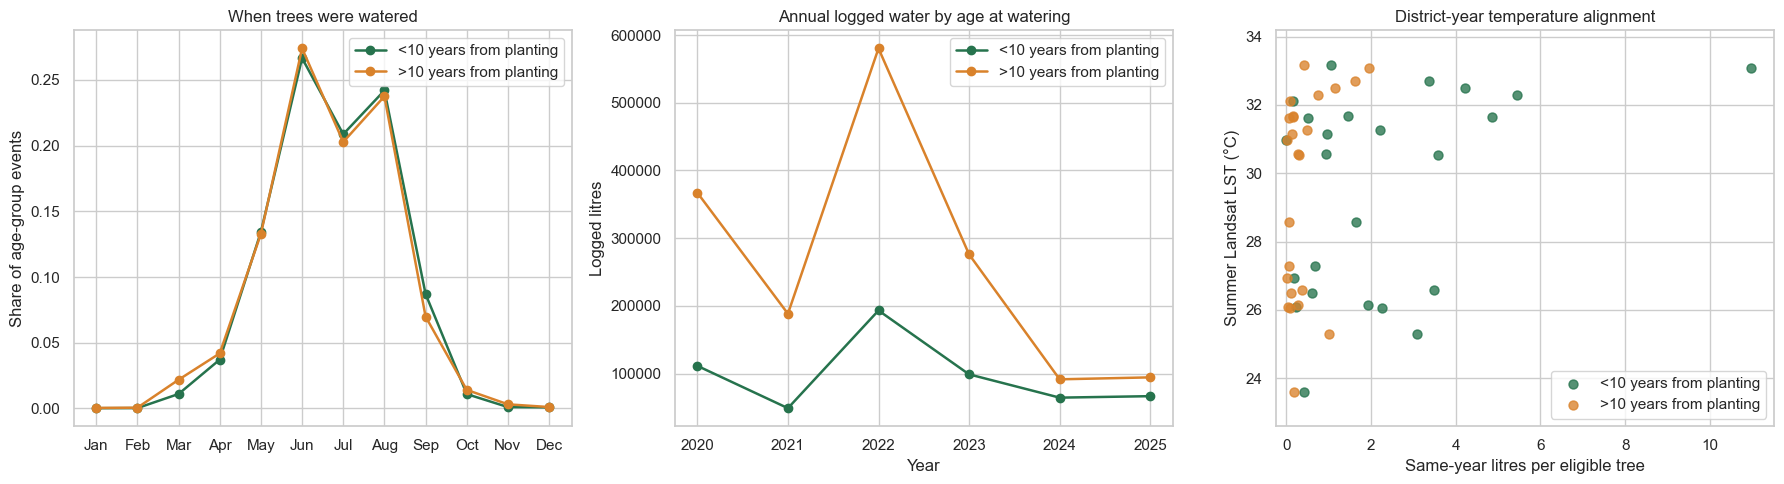

In [9]:
heat_years = sorted(set(heat["Year"]).intersection(set(age_focus["year"].dropna().astype(int))))
if len(heat_years) < 2:
    raise ValueError("Need at least two overlapping heat and watering years for this panel.")

inventory_age_parts = []
for analysis_year in heat_years:
    inventory_age = pd.read_sql_query(
        f'''
        SELECT
            bezirk,
            SUM(CASE
                WHEN CAST(pflanzjahr AS REAL) BETWEEN 1700 AND {analysis_year}
                 AND ({analysis_year} - CAST(pflanzjahr AS REAL)) < 10
                THEN 1 ELSE 0 END) AS young_lt10_inventory_trees,
            SUM(CASE
                WHEN CAST(pflanzjahr AS REAL) BETWEEN 1700 AND {analysis_year}
                 AND ({analysis_year} - CAST(pflanzjahr AS REAL)) > 10
                THEN 1 ELSE 0 END) AS mature_gt10_inventory_trees,
            SUM(CASE
                WHEN CAST(pflanzjahr AS REAL) BETWEEN 1700 AND {analysis_year}
                 AND ({analysis_year} - CAST(pflanzjahr AS REAL)) = 10
                THEN 1 ELSE 0 END) AS age_10_inventory_trees,
            SUM(CASE
                WHEN CAST(pflanzjahr AS REAL) NOT BETWEEN 1700 AND {analysis_year}
                THEN 1 ELSE 0 END) AS unknown_or_future_inventory_trees
        FROM Berlin_trees
        WHERE bezirk IS NOT NULL AND bezirk != ''
        GROUP BY bezirk
        ''',
        con,
    )
    inventory_age["Year"] = analysis_year
    inventory_age_parts.append(inventory_age)
inventory_age_by_year = pd.concat(inventory_age_parts, ignore_index=True)

age_year_district = (
    age_focus[age_focus["year"].isin(heat_years)]
    .groupby(["bezirk_tree", "year", "watering_age_group"], observed=True)
    .agg(
        events=("id", "size"),
        watered_trees=("id", "nunique"),
        total_litres=("litres", "sum"),
    )
    .reset_index()
)
age_year_wide = age_year_district.pivot_table(
    index=["bezirk_tree", "year"],
    columns="watering_age_group",
    values=["events", "watered_trees", "total_litres"],
    fill_value=0,
    observed=True,
)
age_year_wide.columns = [
    f"{age_group}_{metric}" for metric, age_group in age_year_wide.columns.to_flat_index()
]
age_year_wide = age_year_wide.reset_index().rename(columns={"bezirk_tree": "District", "year": "Year"})

temperature_age_panel = (
    heat[heat["Year"].isin(heat_years)][
        [
            "District",
            "Year",
            "Landsat_LST_C",
            "AirTemp_C",
            "HeatIndex_C",
            "TreeCover_Pct",
            "BuiltSurface_Pct",
            "PopulationDensity_per_km2",
        ]
    ]
    .merge(age_year_wide, on=["District", "Year"], how="left")
    .merge(inventory_age_by_year, left_on=["District", "Year"], right_on=["bezirk", "Year"], how="left")
    .drop(columns=["bezirk"])
)

for age_group in ["young_lt10", "mature_gt10"]:
    for metric in ["events", "watered_trees", "total_litres"]:
        column = f"{age_group}_{metric}"
        if column not in temperature_age_panel:
            temperature_age_panel[column] = 0
        temperature_age_panel[column] = temperature_age_panel[column].fillna(0)
    inventory_col = f"{age_group}_inventory_trees"
    temperature_age_panel[f"{age_group}_reach_pct"] = np.where(
        temperature_age_panel[inventory_col] > 0,
        100 * temperature_age_panel[f"{age_group}_watered_trees"] / temperature_age_panel[inventory_col],
        np.nan,
    )
    temperature_age_panel[f"{age_group}_litres_per_inventory_tree"] = np.where(
        temperature_age_panel[inventory_col] > 0,
        temperature_age_panel[f"{age_group}_total_litres"] / temperature_age_panel[inventory_col],
        np.nan,
    )
    temperature_age_panel[f"{age_group}_events_per_1000_inventory"] = np.where(
        temperature_age_panel[inventory_col] > 0,
        1000 * temperature_age_panel[f"{age_group}_events"] / temperature_age_panel[inventory_col],
        np.nan,
    )

temperature_age_panel.to_csv(TABLES / "district_year_age_watering_temperature_panel.csv", index=False)

temperature_metrics = ["Landsat_LST_C", "AirTemp_C", "HeatIndex_C"]
watering_age_metrics = [
    "young_lt10_reach_pct",
    "mature_gt10_reach_pct",
    "young_lt10_litres_per_inventory_tree",
    "mature_gt10_litres_per_inventory_tree",
    "young_lt10_events_per_1000_inventory",
    "mature_gt10_events_per_1000_inventory",
]
age_temperature_rows = []
for temp_metric in temperature_metrics:
    for watering_metric in watering_age_metrics:
        valid = temperature_age_panel[[temp_metric, watering_metric]].dropna()
        if len(valid) >= 4 and valid[temp_metric].nunique() > 1 and valid[watering_metric].nunique() > 1:
            rho, p = spearmanr(valid[temp_metric], valid[watering_metric])
        else:
            rho, p = np.nan, np.nan
        age_temperature_rows.append(
            {
                "temperature_metric": temp_metric,
                "watering_age_metric": watering_metric,
                "n": len(valid),
                "spearman_rho": rho,
                "p_value": p,
            }
        )
age_temperature_correlations = pd.DataFrame(age_temperature_rows)
age_temperature_correlations.to_csv(TABLES / "age_watering_temperature_correlations.csv", index=False)

lst_correlations = age_temperature_correlations[
    age_temperature_correlations["temperature_metric"] == "Landsat_LST_C"
].copy()
display_table(
    temperature_age_panel[
        [
            "District",
            "Year",
            "Landsat_LST_C",
            "young_lt10_reach_pct",
            "mature_gt10_reach_pct",
            "young_lt10_litres_per_inventory_tree",
            "mature_gt10_litres_per_inventory_tree",
        ]
    ]
    .sort_values(["Year", "Landsat_LST_C"], ascending=[True, False]),
    {
        "Landsat_LST_C": "{:.2f}",
        "young_lt10_reach_pct": "{:.2f}",
        "mature_gt10_reach_pct": "{:.2f}",
        "young_lt10_litres_per_inventory_tree": "{:.2f}",
        "mature_gt10_litres_per_inventory_tree": "{:.2f}",
    },
)
display_table(lst_correlations, {"spearman_rho": "{:.2f}", "p_value": "{:.3f}"})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for age_group, color in [("young_lt10", COLORS["green"]), ("mature_gt10", COLORS["orange"])]:
    group_data = age_calendar[age_calendar["watering_age_group"] == age_group]
    axes[0].plot(
        group_data["calendar_month"],
        group_data["event_share_within_group"],
        marker="o",
        linewidth=1.8,
        color=color,
        label=age_group_labels[age_group],
    )
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axes[0].set_ylabel("Share of age-group events")
axes[0].set_title("When trees were watered")
axes[0].legend()

for age_group, color in [("young_lt10", COLORS["green"]), ("mature_gt10", COLORS["orange"])]:
    group_data = age_year_timing[age_year_timing["watering_age_group"] == age_group]
    axes[1].plot(
        group_data["year"],
        group_data["total_litres"],
        marker="o",
        linewidth=1.8,
        color=color,
        label=age_group_labels[age_group],
    )
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Logged litres")
axes[1].set_title("Annual logged water by age at watering")
axes[1].legend(title="")

for age_group, color in [("young_lt10", COLORS["green"]), ("mature_gt10", COLORS["orange"])]:
    axes[2].scatter(
        temperature_age_panel[f"{age_group}_litres_per_inventory_tree"],
        temperature_age_panel["Landsat_LST_C"],
        s=42,
        alpha=0.78,
        color=color,
        label=age_group_labels[age_group],
    )
axes[2].set_xlabel("Same-year litres per eligible tree")
axes[2].set_ylabel("Summer Landsat LST (°C)")
axes[2].set_title("District-year temperature alignment")
axes[2].set_ylim(
    temperature_age_panel["Landsat_LST_C"].min() - 1,
    temperature_age_panel["Landsat_LST_C"].max() + 1,
)
axes[2].set_xlim(left=-0.25)
axes[2].legend()

plt.tight_layout()
plt.savefig(FIGURES / "05_watering_age_timing_temperature.png", dpi=180, bbox_inches="tight")
plt.show()

Age-specific watering is analytically useful, but the temperature comparison is
still too coarse to support an impact claim. A defensible effect estimate would
need event timing, antecedent weather or rainfall, urban-form controls, and a
temperature or vegetation outcome measured close to the watered trees.

## 6. Mortality-field audit

In [10]:
death_audit = heat_raw[
    heat_raw["District"].isin(boroughs)
    & (heat_raw["fclass"] == "admin_level9")
][["District", "Year", "season", "Gestorbene", "Gestorbeneje1.000derBevölkerung"]].copy()

death_pivot = death_audit.pivot(
    index=["District", "Year"],
    columns="season",
    values="Gestorbene",
).reset_index()
death_pivot["summer_equals_winter"] = death_pivot["Summer"].eq(death_pivot["Winter"])

mortality_summary = pd.DataFrame(
    {
        "metric": [
            "District-year observations",
            "Years available",
            "Summer/winter values identical",
            "Contains heat-attributed deaths",
        ],
        "value": [
            len(death_pivot),
            ", ".join(map(str, sorted(death_audit["Year"].unique()))),
            f"{death_pivot['summer_equals_winter'].mean():.0%}",
            "No",
        ],
    }
)
mortality_summary.to_csv(TABLES / "mortality_field_audit.csv", index=False)
display(mortality_summary)

con.close()

,metric,value
0,District-year observations,36
1,Years available,"2015, 2020, 2025"
2,Summer/winter values identical,100%
3,Contains heat-attributed deaths,No


## Interim interpretation

- After removing 111 exact duplicates, the extract contains 58,736 events and
  2.286 million logged litres. Activity peaked in 2022 with 18,238 events and
  806,691 litres, then fell sharply.
- Watering is concentrated: the Gini coefficient of litres across trees is 0.70,
  and the top 10% of watered trees received 57.9% of logged water.
- ID linkage is strong: 11,160 of 11,278 unique watering IDs match the cadastre
  (98.95%).
- Inventory-normalized reach still differs sharply. Friedrichshain-Kreuzberg
  reached 4.05% of all inventoried trees, compared with 0.15% in
  Marzahn-Hellersdorf and 0.18% in Spandau. The maximum/minimum district ratio
  is about 28 for reach and 46 for litres per inventoried tree.
- At district level, watering is more strongly associated with population
  density (Spearman rho 0.71-0.75) and built surface (rho 0.64-0.71) than with
  LST (rho 0.24-0.30). This is consistent with an accessibility or participation
  mechanism, but 12 observations cannot establish one.
- The expected urban-heat structure is visible: tree cover has a strong negative
  association with 2025 summer LST (Spearman rho -0.84).
- Young street trees are preferentially watered. Trees aged 0-9 and 10-19 years
  are represented about 1.94 and 2.36 times as often among watered trees as in
  the street-tree inventory.
- Using age at the time of watering, trees younger than 10 years account for
  13,237 matched complete-year events (22.9%) and 582,862 litres (25.9%).
  Trees older than 10 years account for 43,047 events (74.5%) and 1.598 million
  litres (71.0%); exactly 10-year-old and unknown-age events are kept separate.
- Watering timing is almost identical across the two age groups. June-August
  contains 71.7% of young-tree events and 71.4% of mature-tree events, with June
  the highest month in both groups.
- In the district-year temperature panel for 2020 and 2025, same-year
  age-specific watering has weak-to-moderate positive association with summer
  Landsat LST (Spearman rho 0.27-0.39). This means hotter districts tend to log
  more watering, not that watering reduced temperature.
- The cadastre's geometry metadata must be repaired before using its points in spatial
  joins or maps.
- The mortality columns are annual all-cause counts copied into both seasons. They
  cannot support heat-attributable mortality analysis.
- The next analytical step is a grid- or LOR-level panel combining daily DWD weather,
  recent watering, canopy/imperviousness, and event-matched LST or vegetation stress.